# Phase 8 — Online Learning Benchmark

Implements Chapter 3, Section 3.9 and Chapter 4, Section 4.10 of the dissertation
*"Dynamic Feature Selection for Non-Stationary Environments"*.

Random Forest and XGBoost (Phases 2–7) are batch learners: even in the "dynamic"
framework, they adapt via drift-triggered full retraining, not true instance-by-instance
updating. This notebook adds a fourth benchmark arm -- a genuinely incremental online
regressor (via River) that updates continuously as each new observation arrives, with no
drift detection and no feature selection of its own -- to contextualise how far
drift-triggered retraining of a batch model goes relative to a model that is always
updating.

Two candidates are considered, consistent with Chapter 3, Section 3.9: an online
Lasso-style linear model (L1-regularised) and River's Hoeffding Tree Regressor. Following
Chapter 4, Section 4.10, the choice between them is made empirically, on preliminary
testing, rather than fixed in advance.

**Output:**
- `results/tables/phase8_model_selection.csv` — preliminary comparison of the two candidates
- `results/logs/phase8_online_learner_log.csv` — full per-row log, same format as Phase 7
- `results/tables/phase8_summary.csv` — full metric suite for the selected online learner
- `results/tables/phase8_artifacts.json` — summary metrics, consumed by Phase 9

In [1]:
import sys, os

try:
    from google.colab import drive
    drive.mount('/content/drive')
    PROJECT_ROOT = '/content/drive/MyDrive/dissertation-project'
except ImportError:
    PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))

sys.path.append(os.path.join(PROJECT_ROOT, 'src'))
print('Project root:', PROJECT_ROOT)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project root: /content/drive/MyDrive/dissertation-project


In [2]:
!pip install scikit-learn==1.8.0 statsmodels xgboost river --quiet

In [3]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import data_utils as du
import models as mdl
import metrics as mt
import drift_detectors as dd
import online_learner as ol

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)

## 1. Load artefacts and both streams

Preliminary model selection uses the **real, unmodified test stream** -- a first look at which candidate is generally more reliable before committing to one for the official run. The official run then uses the **same synthetic drift stream as Phase 7**, so the online learner and the dynamic framework are compared on identical data in Phase 9.

In [4]:
artifacts_p2 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase2_artifacts.json'))
artifacts_p4 = mdl.load_artifacts(os.path.join(PROJECT_ROOT, 'results/tables/phase4_artifacts.json'))

feature_cols = artifacts_p2['feature_cols']
target_col = artifacts_p2['target_col']

test_df = pd.read_csv(os.path.join(PROJECT_ROOT, 'data/processed/smart_grid_test.csv'))
injection = dd.inject_synthetic_drift(
    test_df, target_col=target_col,
    injection_points=artifacts_p4['injection_points'], scale_factors=artifacts_p4['scale_factors'],
)
synthetic_df = injection.df

print('Real test stream:', len(test_df), 'rows')
print('Synthetic stream (same as Phase 7):', len(synthetic_df), 'rows')

Real test stream: 10000 rows
Synthetic stream (same as Phase 7): 10000 rows


## 2. Preliminary testing: select the online model

Both candidates process the real test stream, row by row, using the standard online-learning predict-then-learn pattern (predict before the true value is revealed, then update) -- never seeing a row's answer before predicting it.

In [5]:
selected_model_name, selection_comparison_df = ol.select_online_model(test_df, feature_cols, target_col)

print(selection_comparison_df[['display_name', 'MAE', 'RMSE', 'MAPE', 'runtime_s']].to_string(index=False))
print()
print('Selected online model:', ol.ONLINE_MODEL_DISPLAY_NAMES[selected_model_name])

selection_path = os.path.join(PROJECT_ROOT, 'results/tables/phase8_model_selection.csv')
selection_comparison_df.to_csv(selection_path, index=False)
print('Saved preliminary comparison to', selection_path)

                 display_name      MAE       RMSE      MAPE  runtime_s
Online Lasso (L1-regularised) 1.620023   2.010689 35.133174   0.776939
     Hoeffding Tree Regressor 2.788966 128.024549 73.675831   3.229851

Selected online model: Online Lasso (L1-regularised)
Saved preliminary comparison to /content/drive/MyDrive/dissertation-project/results/tables/phase8_model_selection.csv


## 3. Run the selected online learner on the synthetic drift stream

In [6]:
online_result = ol.run_online_learner(selected_model_name, synthetic_df, feature_cols, target_col)
online_summary = ol.summarize_result(online_result, n_features=len(feature_cols))

print(f"Model: {ol.ONLINE_MODEL_DISPLAY_NAMES[selected_model_name]}")
print()
for k, v in online_summary.items():
    print(f'  {k}: {v}')

Model: Online Lasso (L1-regularised)

  MAE: 1.8969333689709136
  RMSE: 2.4553573489972225
  R2: 0.6272528072819218
  MAPE: 35.572066005311626
  Adjusted_R2: 0.6268049284081242
  Penalised_MAE: 2.3828587058725126
  Penalised_Loss: 7.927550606527946
  total_runtime_s: 0.6128371899999934
  selection_runtime_s: 0.0
  n_drift_events: 0
  n_retrains: 0
  mean_feature_stability_index: 1.0
  mean_importance_consistency: nan
  feature_switch_rate: 0.0
  mean_adaptation_time_rows: nan
  n_adaptation_events_recovered: 0


## 4. Build the full per-row log (same format as Phase 7)

`drift_flag` is always False and `active_features` never changes here -- this benchmark has no drift detection or feature selection component, by design (Chapter 3, Section 3.9); it is included for exactly this contrast in Phase 9.

In [7]:
full_log_df = pd.DataFrame({
    'row_index': np.arange(len(online_result.predictions)),
    'y_true': online_result.y_true,
    'prediction': online_result.predictions,
    'abs_error': online_result.errors,
    'drift_flag': False,
    'active_features': ', '.join(feature_cols),
})

log_path = os.path.join(PROJECT_ROOT, 'results/logs/phase8_online_learner_log.csv')
os.makedirs(os.path.dirname(log_path), exist_ok=True)
full_log_df.to_csv(log_path, index=False)

print('Saved full per-row log to', log_path, f'({len(full_log_df)} rows)')
full_log_df.head()

Saved full per-row log to /content/drive/MyDrive/dissertation-project/results/logs/phase8_online_learner_log.csv (10000 rows)


,row_index,y_true,prediction,abs_error,drift_flag,active_features
0,0,11.022376,0.000000,11.022376,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
1,1,2.970304,0.220448,2.749856,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
2,2,10.862895,8.661213,2.201682,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
3,3,7.746257,1.258250,6.488007,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."
4,4,6.000676,-0.509304,6.509980,False,"Voltage (V), Reactive Power (kVAR), Power Fact..."


## 5. Visualise: online learner error over time vs the synthetic drift points

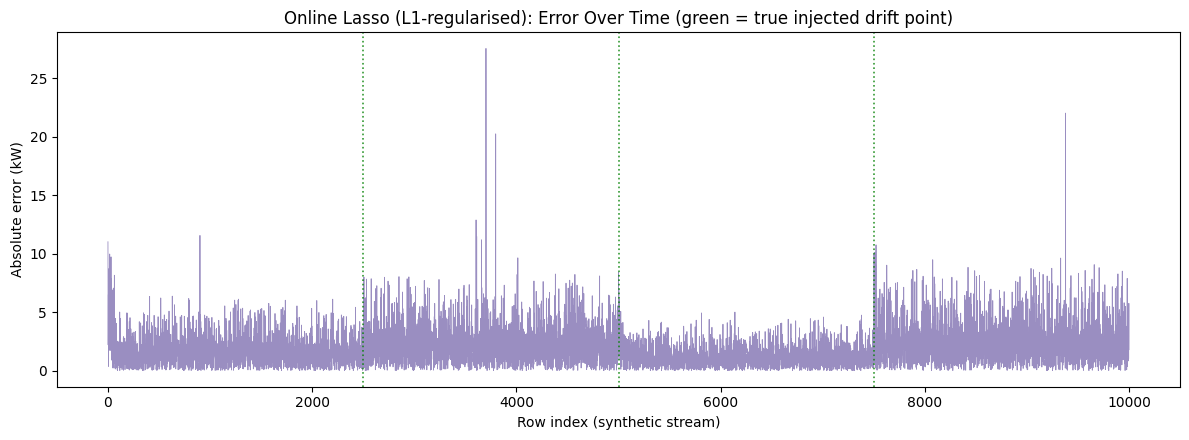

Saved figure to /content/drive/MyDrive/dissertation-project/results/figures/phase8_online_learner.png


In [8]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(full_log_df['row_index'], full_log_df['abs_error'], color='#8172B2', linewidth=0.6, alpha=0.8)
for idx in injection.true_drift_indices:
    ax.axvline(idx, color='green', linestyle=':', linewidth=1.2, alpha=0.8)
ax.set_xlabel('Row index (synthetic stream)')
ax.set_ylabel('Absolute error (kW)')
ax.set_title(f'{ol.ONLINE_MODEL_DISPLAY_NAMES[selected_model_name]}: Error Over Time (green = true injected drift point)')

plt.tight_layout()
fig_path = os.path.join(PROJECT_ROOT, 'results/figures/phase8_online_learner.png')
os.makedirs(os.path.dirname(fig_path), exist_ok=True)
plt.savefig(fig_path, dpi=150)
plt.show()
print('Saved figure to', fig_path)

## 6. Quick context: online learner vs Phase 7's dynamic framework

Not the official Phase 9 comparison -- a same-stream preview only, since both logs already exist. The official three-way comparison (static vs dynamic vs online), on the full metric suite with proper framing, is Phase 9.

In [9]:
phase7_summary_path = os.path.join(PROJECT_ROOT, 'results/tables/phase7_summary.csv')
if os.path.exists(phase7_summary_path):
    phase7_df = pd.read_csv(phase7_summary_path)
    dynamic_mae = phase7_df.loc[phase7_df['system'] == 'Dynamic framework', 'MAE'].iloc[0]
    static_mae = phase7_df.loc[phase7_df['system'] == 'Static (no adaptation)', 'MAE'].iloc[0]

    preview_df = pd.DataFrame([
        {'system': 'Static (no adaptation, XGBoost)', 'MAE': static_mae},
        {'system': 'Dynamic framework (Phase 7)', 'MAE': dynamic_mae},
        {'system': f'Online learner ({ol.ONLINE_MODEL_DISPLAY_NAMES[selected_model_name]})', 'MAE': online_summary['MAE']},
    ])
    print(preview_df.to_string(index=False))
else:
    print('Phase 7 summary not found -- run Phase 7 first for this preview.')

                                        system      MAE
               Static (no adaptation, XGBoost) 2.313443
                   Dynamic framework (Phase 7) 2.150848
Online learner (Online Lasso (L1-regularised)) 1.896933


## 7. Persist artefacts for Phase 9

In [10]:
summary_path = os.path.join(PROJECT_ROOT, 'results/tables/phase8_summary.csv')
pd.DataFrame([{'system': ol.ONLINE_MODEL_DISPLAY_NAMES[selected_model_name], **online_summary}]).to_csv(summary_path, index=False)

artifacts = {
    'selected_online_model': selected_model_name,
    'preliminary_selection': selection_comparison_df.to_dict('records'),
    'online_summary': {k: (float(v) if isinstance(v, (int, float, np.floating)) else v) for k, v in online_summary.items()},
    'log_path': 'results/logs/phase8_online_learner_log.csv',
}
artifacts_path = os.path.join(PROJECT_ROOT, 'results/tables/phase8_artifacts.json')
mdl.save_artifacts(artifacts, artifacts_path)

print('Saved summary to', summary_path)
print('Saved artefacts to', artifacts_path)

Saved summary to /content/drive/MyDrive/dissertation-project/results/tables/phase8_summary.csv
Saved artefacts to /content/drive/MyDrive/dissertation-project/results/tables/phase8_artifacts.json


## Summary

This notebook implements Chapter 3, Section 3.9 and Chapter 4, Section 4.10. Two candidate online learners were compared empirically on the real test stream, and the better-performing one was run on the same synthetic drift stream used for the static baseline (Phase 2) and dynamic framework (Phase 7), producing a log in the same format so all three systems can be compared directly and fairly in Phase 9 -- the official three-way comparison and the final piece of the experimental design.